# Carbon isotope envelopes

Calculate nominal isotope probabilities for a carbon-only model.

Each carbon independently contributes a 13C isotope with a specified probability. The binomial coefficients combine all configurations with the same number of heavier atoms. This isolates the carbon contribution to a peptide envelope.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import binom

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

C20 modal offset 0 | displayed probability 1.000000
C50 modal offset 0 | displayed probability 1.000000
C90 modal offset 0 | displayed probability 0.999999


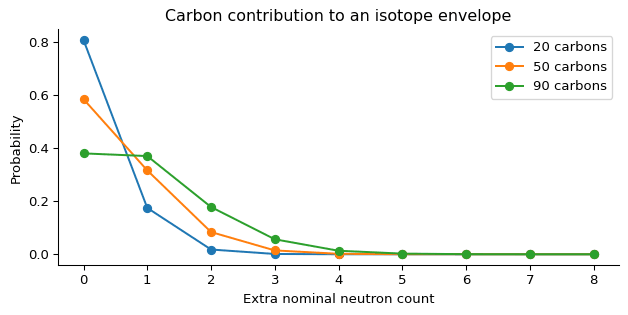

In [2]:
k = np.arange(9)
fig, ax = plt.subplots(figsize=(6.5, 3.2), constrained_layout=True)
for count in [20, 50, 90]:
    pmf = binom.pmf(k, count, 0.0107)
    ax.plot(k, pmf, "o-", label=f"{count} carbons")
    print(f"C{count} modal offset {k[pmf.argmax()]} | displayed probability {pmf.sum():.6f}")
assert np.isclose(binom.pmf(np.arange(91), 90, 0.0107).sum(), 1)
ax.set(
    xlabel="Extra nominal neutron count",
    ylabel="Probability",
    title="Carbon contribution to an isotope envelope",
)
ax.legend()
plt.show()

## Interpreting the result

The monoisotopic peak loses probability as carbon count rises. Other elements, fine structure and instrument resolution are outside this model.

## Exercise

Find the smallest carbon count where M+1 is taller than M.

## References

[NIST, atomic weights and isotopic compositions](https://physics.nist.gov/Comp)